# Revenu médian, APL et hôpitaux par département
Analyse des relations entre revenu médian, accessibilité aux soins (APL) et densité hospitalière.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import geopandas as gpd
from conversion_data_filosofi import conversion_filosofi_pandas

RACINE = Path.cwd()

Le dossier de destination existe déjà : data/FILOSOFI_CC_csv
      COM_INSEE GEO_OBJECT FILOSOFI_MEASURE  OBS_VALUE
16958     01162        COM           MED_SL        NaN
17092     01190        COM           MED_SL        NaN
18390     01051        COM           MED_SL        NaN
21112     01311        COM           MED_SL        NaN
21690     02146        COM           MED_SL        NaN


## 1. Revenu médian par département

In [2]:
df_departement_revenu_median = conversion_filosofi_pandas("DEP", "PR_MD60")
df_departement_revenu_median.rename(columns={
        df_departement_revenu_median.columns[0]: "DEP",
        df_departement_revenu_median.columns[3]: "revenu_median",
    },
    inplace=True,
)
# vérification que DEP est bien au format string
df_departement_revenu_median["DEP"] = df_departement_revenu_median["DEP"].astype(str).str.strip()

/tmp/ipykernel_100198/3310408038.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_departement_revenu_median.rename(columns={


Les données de Filosofi sont mobilisées pour obtenir le revenu médian à l'échelle départementale.

Cependant, cet indicateur ne permet pasde rendre compte des écarts de revenus qui peuvent exister entre les communes ou au sein d'un même département.

## 2. APL moyenne par département (pondérée par la population)

In [3]:
apl_fin = pd.read_csv(RACINE / "data/processed/apl_fin.csv", dtype={"COM_INSEE": str, "DEP": str})
apl_fin = apl_fin[["COM_INSEE", "apl", "pop_tot", "DEP"]]
apl_fin["APL*habitant"] = apl_fin["apl"] * apl_fin["pop_tot"]

apl_par_departement = apl_fin.groupby("DEP").agg({"APL*habitant": "sum", "pop_tot": "sum"}).reset_index()
apl_par_departement["apl"] = apl_par_departement["APL*habitant"] / apl_par_departement["pop_tot"]
apl_par_departement["DEP"] = apl_par_departement["DEP"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()

L'accessibilité potentielle localisée (APL) est ici agrégée à l'échelle départementale en tenant compte de la population de chaque commune. La pondération consiste à multiplier l'APL communale par la population, puis à rapporter la somme obtenue à la population totale du département.

Cette méthode à l'avantage de fournir l'APL par personne au sein du département et non seulement une moyenne des APL des différentes communes.

## 3. Hôpitaux par département

In [4]:
df_hopitaux = pd.read_csv(RACINE / "data" / "processed" / "BASE_loc_hopitaux.csv", dtype={"COM_INSEE": str, "INSEE_DEP": str})
df_hopitaux = df_hopitaux[["name", "INSEE_DEP"]]
hopitaux_par_departement = (
    df_hopitaux.groupby("INSEE_DEP").agg({"name": "count"}).reset_index().rename(columns={"name": "nb_hopitaux"})
)
hopitaux_par_departement["INSEE_DEP"] = hopitaux_par_departement["INSEE_DEP"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()

La base hospitalière est regroupée selon le code du département (`INSEE_DEP`) afin de compter les établissements recensés dans chacun d'eux.

Ce décompte mesure le nombre d'établissements, mais ne renseigne pas directement sur leur capacité d'accueil, leur taille, les spécialités proposées ou leur activité. Deux départements ayant le même nombre d'établissements peuvent ainsi présenter des offres hospitalières très différentes.

## 4. Fusion des jeux de données

In [5]:
df = pd.merge(df_departement_revenu_median, apl_par_departement, on="DEP", how="left")
df = pd.merge(df, hopitaux_par_departement, left_on="DEP", right_on="INSEE_DEP", how="left")

df.set_index("DEP", inplace=True)
df = df[["revenu_median", "pop_tot", "apl", "nb_hopitaux"]]
df["nb_hopitaux"] = df["nb_hopitaux"].fillna(0).astype(int)
df["revenu_median"] = df["revenu_median"].fillna(0).astype(int)
df["nb_hopitaux_par_habitant"] = df["nb_hopitaux"] / df["pop_tot"]

print(len(df_departement_revenu_median), len(df))
print(df.head())

# Réinitialisation de l'index pour faciliter l'exploitation graphique
df_reset = df.reset_index()

97 97
     revenu_median   pop_tot       apl  nb_hopitaux  nb_hopitaux_par_habitant
DEP                                                                          
49              11  828151.0  3.957212           25                  0.000030
07              15  333229.0  2.924378           28                  0.000084
85               9  706343.0  2.922146           16                  0.000023
36              15  216809.0  2.614507            9                  0.000042
41              14  328953.0  2.769208           11                  0.000033


/tmp/ipykernel_100198/2571053709.py:4: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index("DEP", inplace=True)


Les trois sources sont rapprochées à partir du code départemental. Le tableau final rassemble le revenu médian, la population totale, l'APL moyenne pondérée et le nombre d'hôpitaux. Le nombre d'hôpitaux par habitant est ensuite calculé pour tenir compte des différences de taille démographique entre départements.

Cette normalisation facilite les comparaisons, mais le ratio obtenu reste un indicateur de densité d'établissements rapportée à la population. Il ne constitue pas une mesure directe de l'accès effectif aux soins.

## 5. Graphiques 

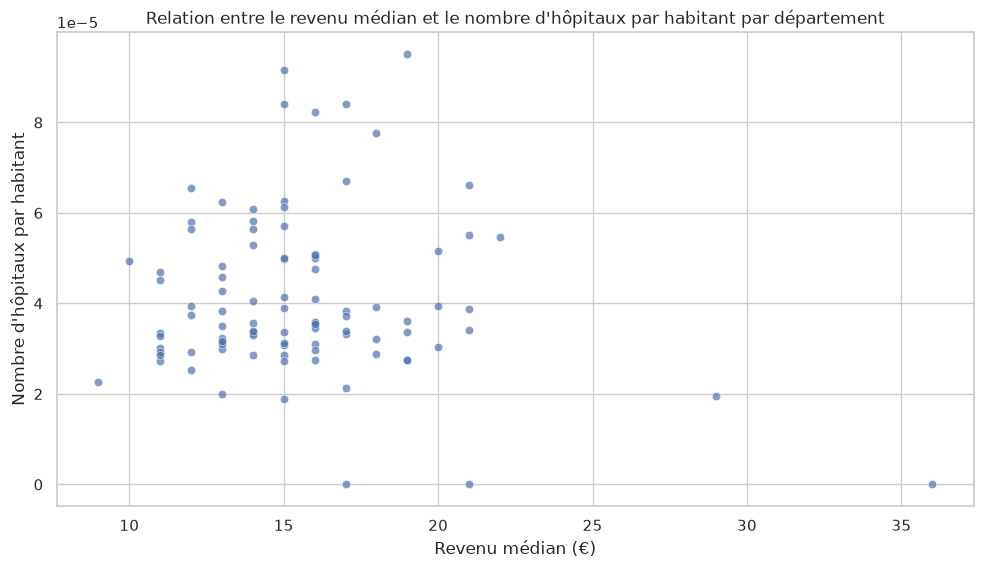

In [6]:
sns.set_theme(style="whitegrid")

# Revenu médian (X) vs nb d'hôpitaux par habitant (Y)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_reset, x="revenu_median", y="nb_hopitaux_par_habitant", alpha=0.7)
plt.title("Relation entre le revenu médian et le nombre d'hôpitaux par habitant par département")
plt.xlabel("Revenu médian (€)")
plt.ylabel("Nombre d'hôpitaux par habitant")
plt.tight_layout()
plt.savefig(RACINE / "figures" / "graph_revenu_vs_hopitaux.png", dpi=300)
plt.show()

Ce premier nuage de points met en regard le revenu médian départemental et le nombre d'hôpitaux rapporté à la population. Il permet d'observer si les départements présentant des niveaux de revenus différents se caractérisent également par des densités hospitalières différentes. 
A l'oeil, aucun résultat évident ne semble se dessiner même si une corrélation positive pourrait être envisagée, en enlevant les 3 points en bas à droite du graphique. 



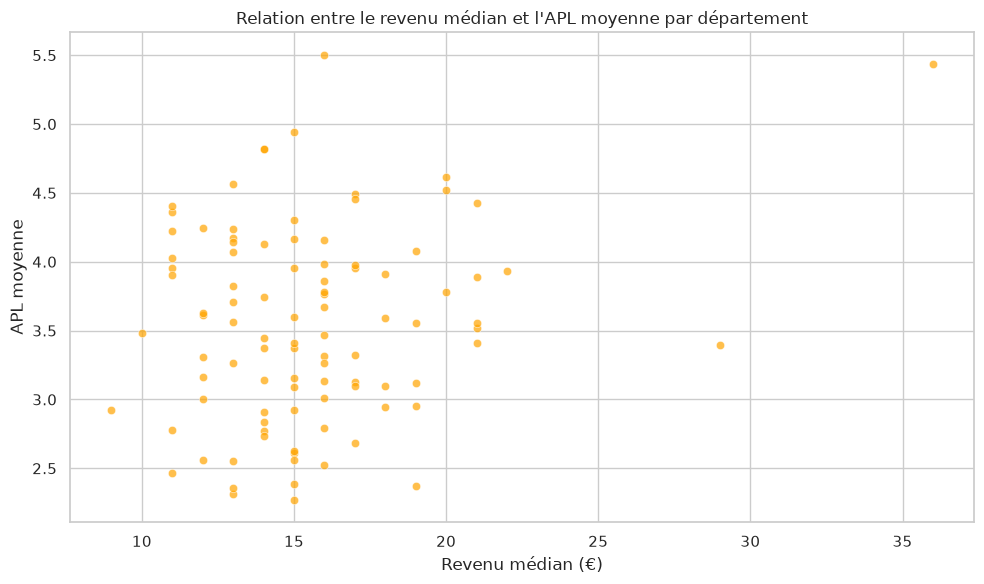

In [7]:
# Revenu médian (X) vs APL (Y)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_reset, x="revenu_median", y="apl", alpha=0.7, color="orange")
plt.title("Relation entre le revenu médian et l'APL moyenne par département")
plt.xlabel("Revenu médian (€)")
plt.ylabel("APL moyenne")
plt.tight_layout()
plt.savefig(RACINE / "figures" / "graph_revenu_vs_apl.png", dpi=300)
plt.show()

Ce graphique compare le revenu médian départemental à l'APL moyenne par habitant. Il permet d'examiner si les territoires aux revenus médians les plus élevés disposent également, en moyenne, d'une meilleure accessibilité potentielle aux soins de ville.

Là aussi une corrélation plutôt positive semble se dessiner. 


## 6. Cartes de France (APL, Revenu Médian, hopitaux par habitants)

In [8]:
# GeoJSON officiel des départements français
geojson_url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements.geojson"
gdf_deps = gpd.read_file(geojson_url)
gdf_deps["code"] = gdf_deps["code"].astype(str).str.strip()

# Fusion des données géographiques avec les données
gdf_merged = gdf_deps.merge(df_reset, left_on="code", right_on="DEP", how="left")

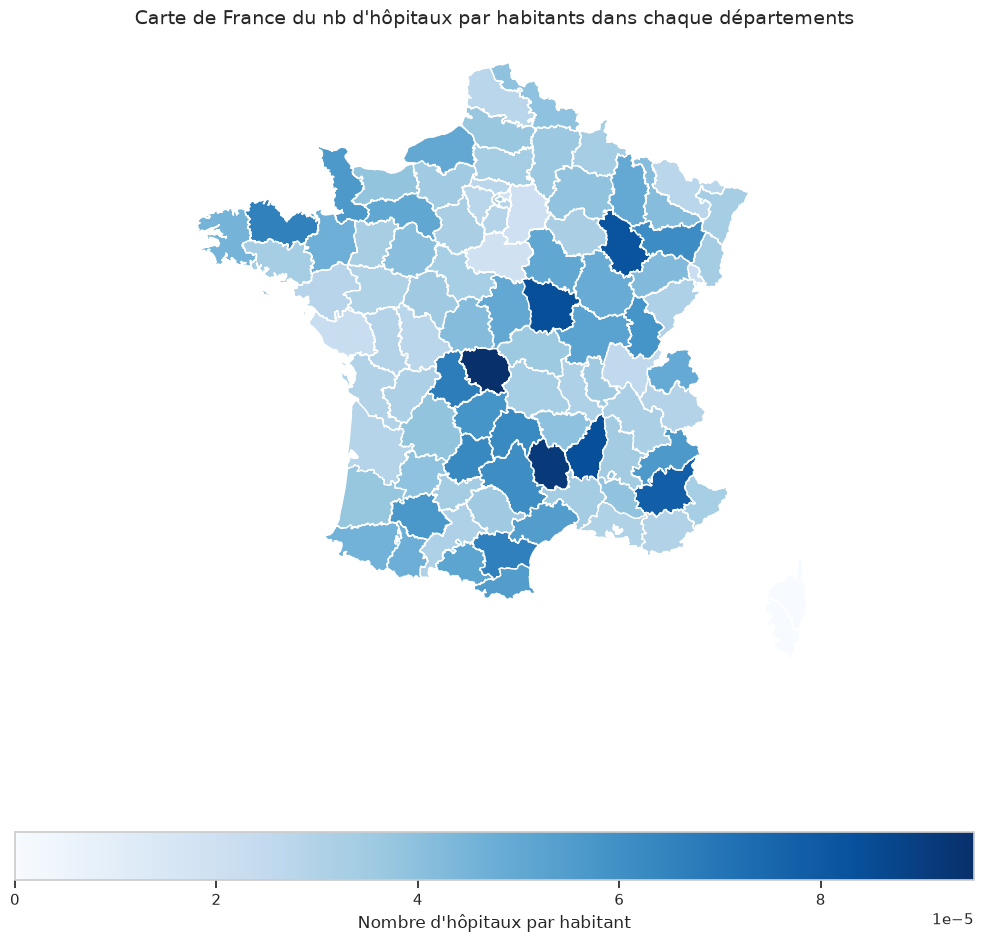

In [9]:
# Nombre d'hôpitaux par habitant
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
gdf_merged.plot(
    column="nb_hopitaux_par_habitant",
    ax=ax,
    legend=True,
    cmap="Blues",
    legend_kwds={"label": "Nombre d'hôpitaux par habitant", "orientation": "horizontal"},
    missing_kwds={"color": "lightgrey", "label": "Données manquantes"},
)
ax.set_title("Carte de France du nb d'hôpitaux par habitants dans chaque départements", fontsize=14)
ax.axis("off")
plt.tight_layout()
plt.savefig(RACINE / "figures" / "carte_nb_hopitaux_par_habitant.png", dpi=300)
plt.show()

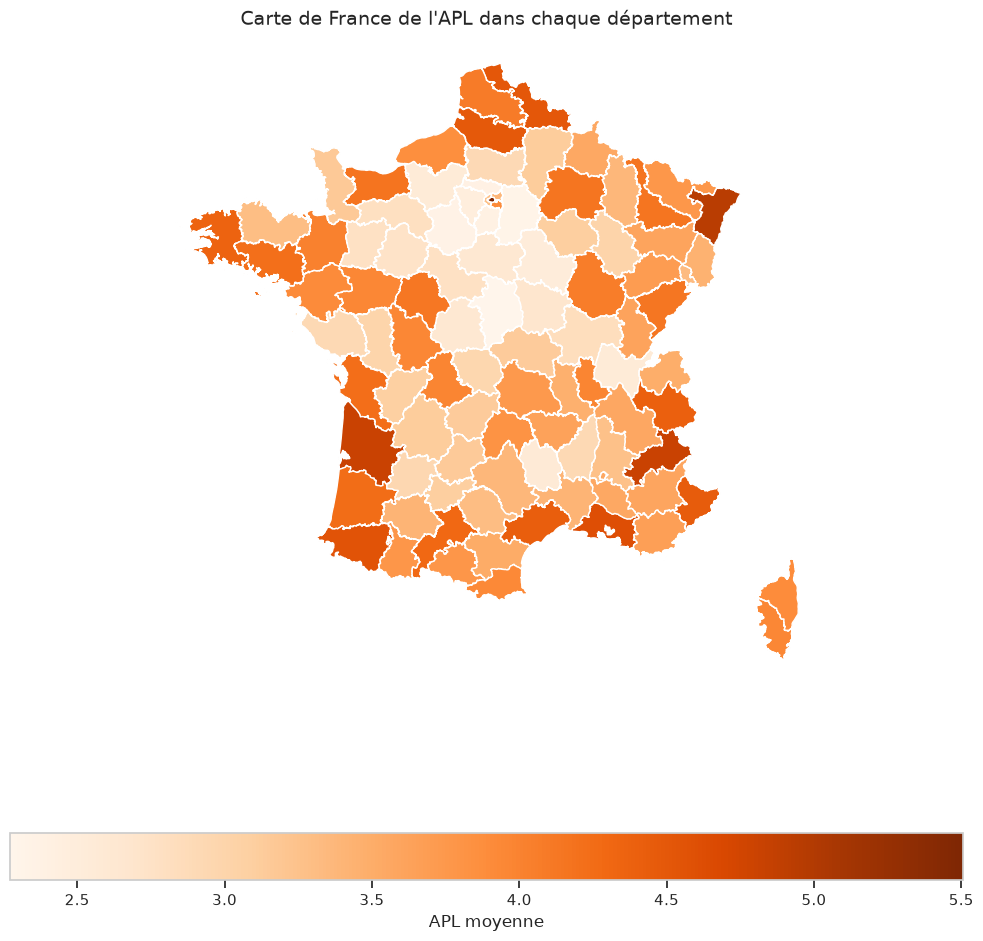

In [10]:
# APL
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
gdf_merged.plot(
    column="apl",
    ax=ax,
    legend=True,
    cmap="Oranges",
    legend_kwds={"label": "APL moyenne", "orientation": "horizontal"},
    missing_kwds={"color": "lightgrey", "label": "Données manquantes"},
)
ax.set_title("Carte de France de l'APL dans chaque département", fontsize=14)
ax.axis("off")
plt.tight_layout()
plt.savefig(RACINE / "figures" / "carte_apl.png", dpi=300)
plt.show()

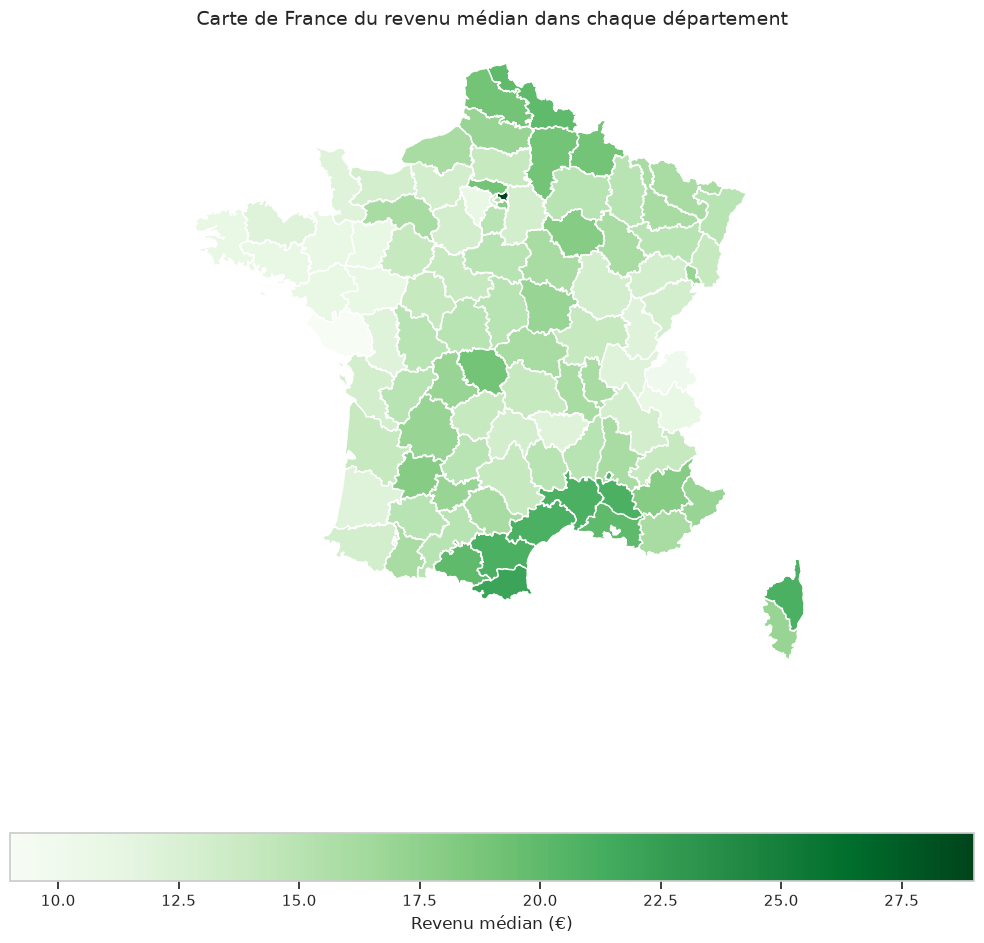

In [11]:
# Revenu médian
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
gdf_merged.plot(
    column="revenu_median",
    ax=ax,
    legend=True,
    cmap="Greens",
    legend_kwds={"label": "Revenu médian (€)", "orientation": "horizontal"},
    missing_kwds={"color": "lightgrey", "label": "Données manquantes"},
)
ax.set_title("Carte de France du revenu médian dans chaque département", fontsize=14)
ax.axis("off")
plt.tight_layout()
plt.savefig(RACINE / "figures" / "carte_revenu_median.png", dpi=300)
plt.show()

La mise en carte permet de replacer les indicateurs dans leur contexte géographique et de repérer d'éventuelles concentrations ou oppositions territoriales. La lecture conjointe des cartes est particulièrement utile : un département peut présenter un revenu médian relativement élevé sans disposer des mêmes niveaux d'APL ou de densité hospitalière qu'un autre territoire.



## GRAPHIQUES PAUVRETE

## Analyse du taux de pauvreté

Cette partie complète l'approche par le revenu médian en mobilisant le taux de pauvreté départemental. Alors que le revenu médian renseigne sur le niveau de vie situé au milieu de la distribution, le taux de pauvreté mesure la part de la population située sous un seuil de pauvreté défini.

Le croisement avec les indicateurs de soins permet d'examiner si les départements davantage concernés par la pauvreté présentent également des niveaux différents d'accessibilité potentielle aux soins ou de densité hospitalière.

In [12]:
# TAUX DE PAUVRETÉ

df_pauvrete = conversion_filosofi_pandas("DEP", "PR_MD60")
df_pauvrete.rename(columns={
        df_pauvrete.columns[0]: "DEP",
        df_pauvrete.columns[3]: "taux_pauvrete",
    },
    inplace=True,
)
df_pauvrete["DEP"] = df_pauvrete["DEP"].astype(str).str.strip()
df_pauvrete = df_pauvrete[["DEP", "taux_pauvrete"]]

# Ajout au tableau existant 
df_reset = df_reset.merge(df_pauvrete, on="DEP", how="left")



/tmp/ipykernel_100198/4021553397.py:4: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_pauvrete.rename(columns={


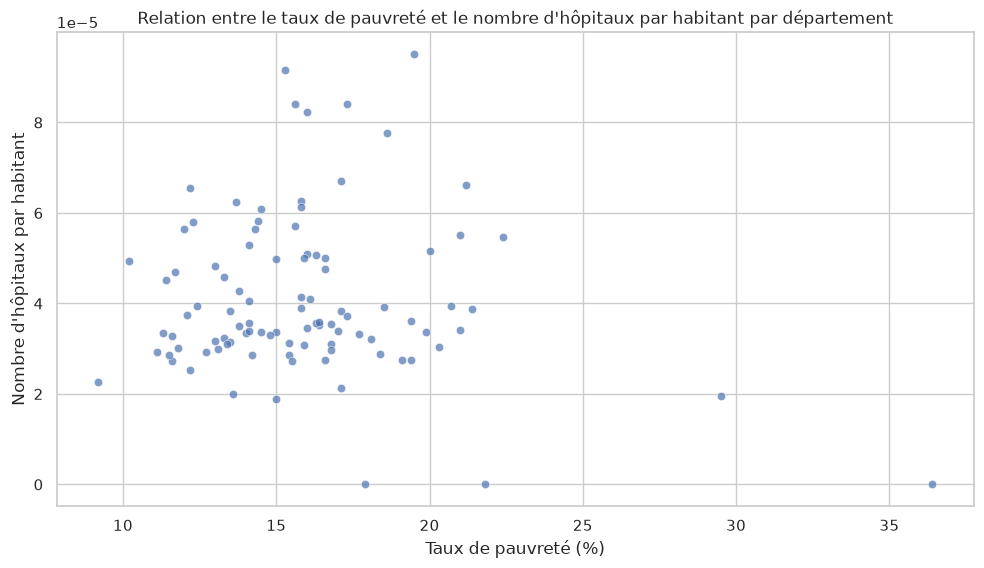

In [13]:
# Graphique 1 : taux de pauvreté (X) vs nb d'hôpitaux par habitant (Y)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_reset, x="taux_pauvrete", y="nb_hopitaux_par_habitant", alpha=0.7)
plt.title("Relation entre le taux de pauvreté et le nombre d'hôpitaux par habitant par département")
plt.xlabel("Taux de pauvreté (%)")
plt.ylabel("Nombre d'hôpitaux par habitant")
plt.tight_layout()
plt.savefig(RACINE / "figures" / "graph_pauvrete_vs_hopitaux.png", dpi=300)
plt.show()

Ce nuage de points met en relation le taux de pauvreté et le nombre d'hôpitaux par habitant. Il permet de rechercher si les départements où la pauvreté est plus répandue disposent d'une densité hospitalière différente.

On observe un résultat qui peut s'avérer surprenant. Il semble que le nombre d'hopitaux par habitant est plus élevé là où le taux de pauvreté l'est aussi. 

Il convient tout de même de distinguer la présence d'établissements de leur accessibilité réelle : la distance, les temps de trajet, les capacités d'accueil et les spécialités disponibles ne sont pas pris en compte dans ce ratio.

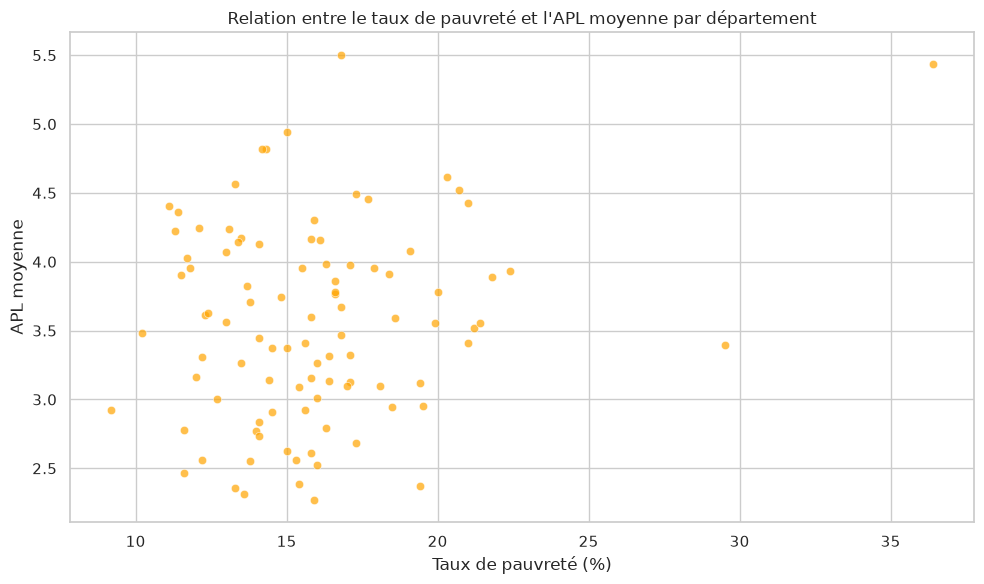

In [14]:
# Graphique 2 : taux de pauvreté (X) vs APL (Y)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_reset, x="taux_pauvrete", y="apl", alpha=0.7, color="orange")
plt.title("Relation entre le taux de pauvreté et l'APL moyenne par département")
plt.xlabel("Taux de pauvreté (%)")
plt.ylabel("APL moyenne")
plt.tight_layout()
plt.savefig(RACINE / "figures" / "graph_pauvrete_vs_apl.png", dpi=300)
plt.show()

Ce second graphique confronte le taux de pauvreté à l'APL moyenne pondérée. Il apporte un éclairage complémentaire sur les inégalités territoriales, en rapprochant une caractéristique socio-économique de la population d'un indicateur d'accessibilité aux professionnels de santé.



## Carte du taux de pauvreté

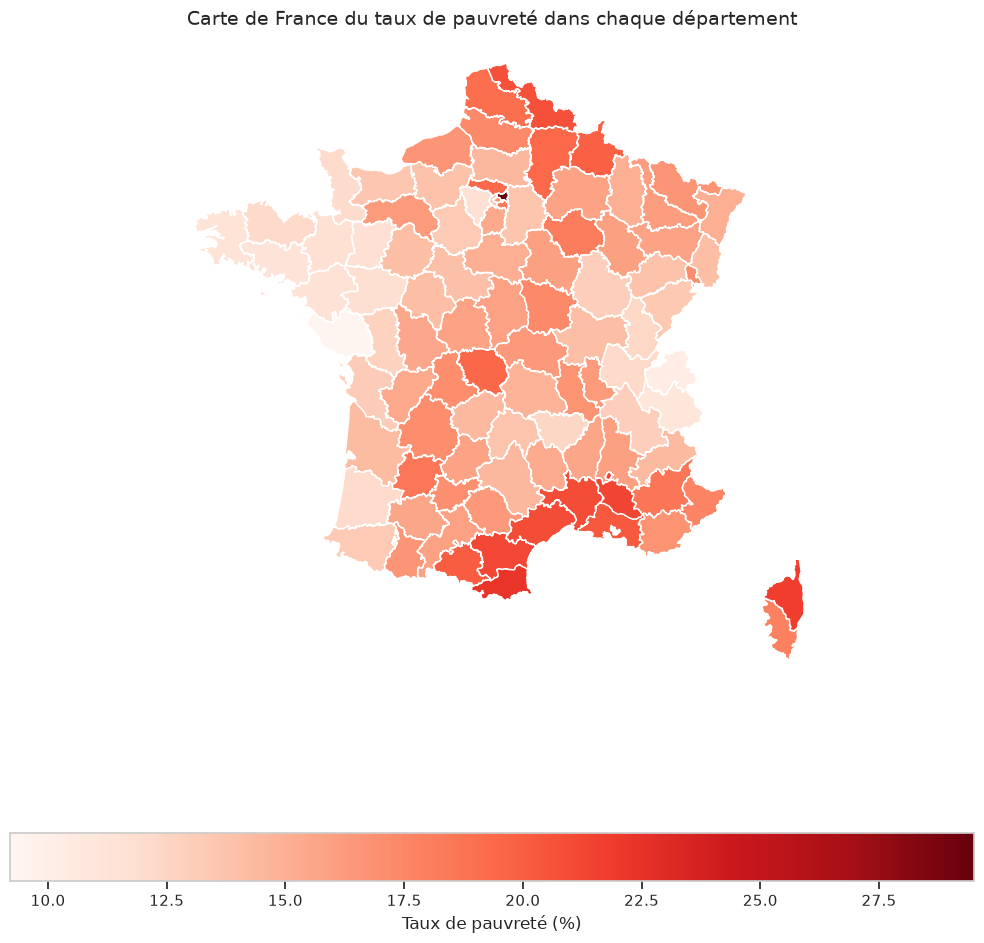

In [15]:

gdf_merged = gdf_deps.merge(df_reset, left_on="code", right_on="DEP", how="left")

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
gdf_merged.plot(
    column="taux_pauvrete",
    ax=ax,
    legend=True,
    cmap="Reds",
    legend_kwds={"label": "Taux de pauvreté (%)", "orientation": "horizontal"},
    missing_kwds={"color": "lightgrey", "label": "Données manquantes"},
)
ax.set_title("Carte de France du taux de pauvreté dans chaque département", fontsize=14)
ax.axis("off")
plt.tight_layout()
plt.savefig(RACINE / "figures" / "carte_taux_pauvrete.png", dpi=300)
plt.show()

La carte du taux de pauvreté permet d'identifier la répartition géographique de cet indicateur et de la comparer visuellement aux cartes du revenu médian, de l'APL et de la densité hospitalière.

La comparaison de ces représentations peut faire ressortir des territoires cumulant plusieurs fragilités. Une analyse plus fine à l'échelle communale, complétée par des informations sur les distances et les capacités hospitalières, serait nécessaire pour approfondir ces constats.